
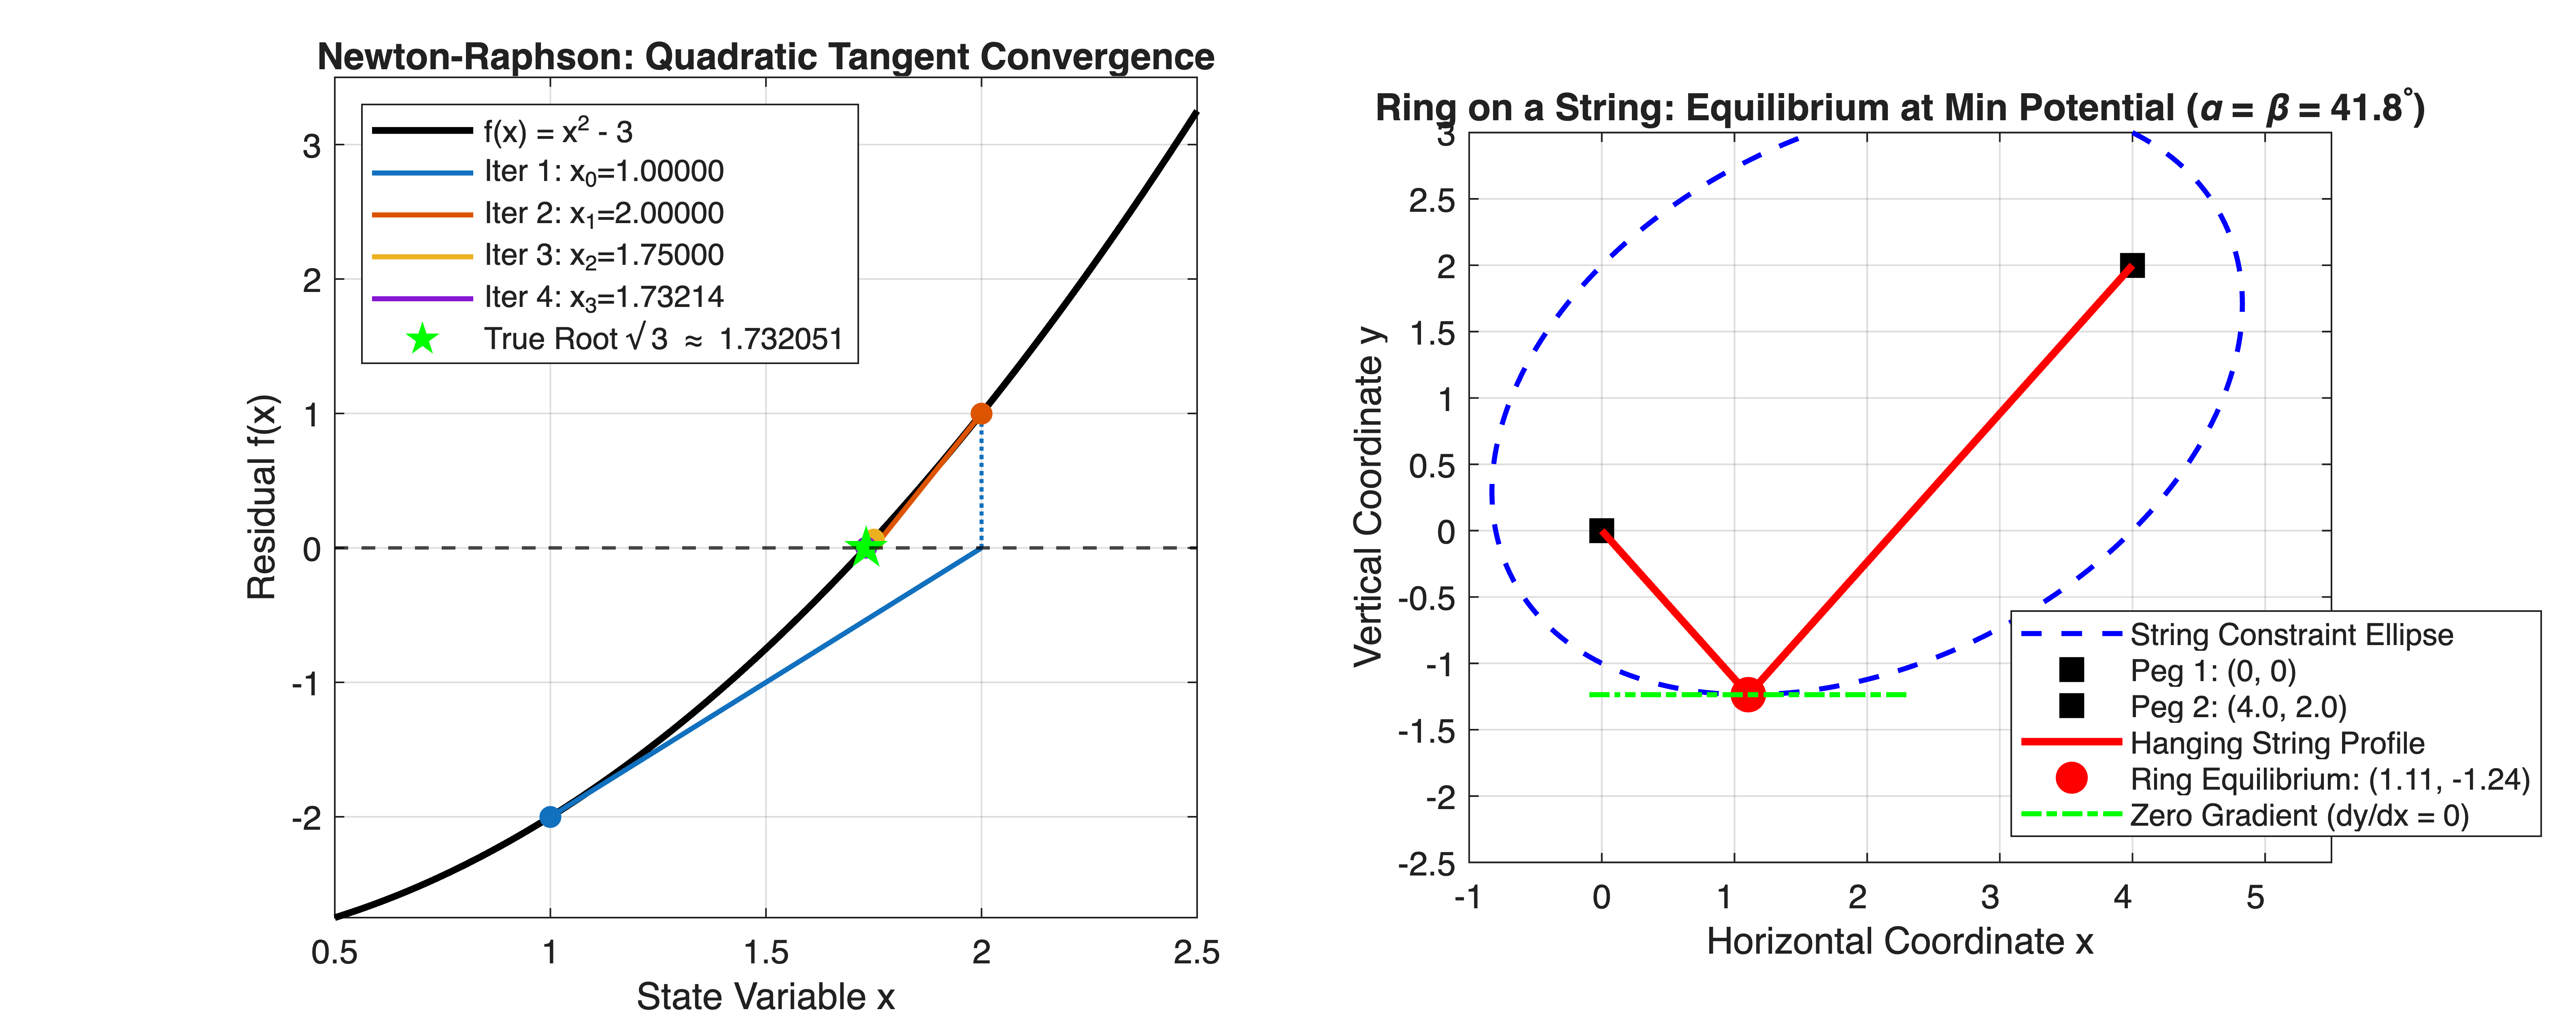

In [1]:
%% MIT 18.01 Lecture 13: Newton's Method & Mechanical Equilibrium Simulation
% Mathematical Tool Application: Used for nonlinear algebraic loop convergence
% in implicit ODE solvers (Newton-Raphson) and physical plant static equilibrium trimming.


clear; clc; close all;


%% Part 1: Newton-Raphson Method Iteration Trajectory (f(x) = x^2 - 3)
f = @(x) x.^2 - 3;
df = @(x) 2 * x;
true_root = sqrt(3);


% Iteration parameters from lecture
x_iter = zeros(1, 5);
x_iter(1) = 1.0; % Initial guess x0
max_steps = 4;


for k = 1:max_steps
    x_iter(k+1) = x_iter(k) - f(x_iter(k)) / df(x_iter(k));
end


figure('Color', 'w', 'Position', [100, 100, 1250, 500]);


subplot(1, 2, 1);
x_span = linspace(0.5, 2.5, 400);
plot(x_span, f(x_span), 'k-', 'LineWidth', 2.0, 'DisplayName', 'f(x) = x^2 - 3'); hold on;
yline(0, 'k--', 'LineWidth', 1.0, 'HandleVisibility', 'off');


% Plot successive tangent projections
colors = lines(max_steps);
for k = 1:max_steps
    xk = x_iter(k);
    yk = f(xk);
    x_next = x_iter(k+1);


    % Tangent segment from (xk, yk) to (x_next, 0)
    plot([xk, x_next], [yk, 0], '-', 'Color', colors(k, :), 'LineWidth', 1.5, ...
        'DisplayName', sprintf('Iter %d: x_{%d}=%.5f', k, k-1, xk));


    % Vertical projection to next evaluation point
    plot([x_next, x_next], [0, f(x_next)], ':', 'Color', colors(k, :), 'LineWidth', 1.2, 'HandleVisibility', 'off');
    plot(xk, yk, 'o', 'MarkerFaceColor', colors(k, :), 'Color', colors(k, :), 'HandleVisibility', 'off');
end


plot(true_root, 0, 'gp', 'MarkerSize', 12, 'MarkerFaceColor', 'g', ...
    'DisplayName', sprintf('True Root \\surd 3 \\approx %.6f', true_root));


grid on;
xlim([0.8, 2.3]); ylim([-2.5, 3.5]);
xlabel('State Variable x');
ylabel('Residual f(x)');
title('Newton-Raphson: Quadratic Tangent Convergence');
legend('Location', 'northwest');


%% Part 2: Ring on a String Potential Energy Minimization
% Geometry parameters: Fixed suspension pegs at (0, 0) and (a, b)
a_peg = 4.0;
b_peg = 2.0;
L_string = 6.0; % String length (L > sqrt(a^2 + b^2))


% Theoretical equilibrium derived in lecture:
% y* = 0.5 * (b - sqrt(L^2 - a^2))
% x* = (a / 2) * (1 - b / sqrt(L^2 - a^2))
y_opt = 0.5 * (b_peg - sqrt(L_string^2 - a_peg^2));
x_opt = (a_peg / 2.0) * (1.0 - b_peg / sqrt(L_string^2 - a_peg^2));


% Constraint Ellipse: sqrt(x^2 + y^2) + sqrt((x-a)^2 + (y-b)^2) = L
subplot(1, 2, 2);
fimplicit(@(x, y) sqrt(x.^2 + y.^2) + sqrt((x - a_peg).^2 + (y - b_peg).^2) - L_string, ...
    [-2, 6, -3, 3], 'b--', 'LineWidth', 1.5, 'DisplayName', 'String Constraint Ellipse'); hold on;


% Plot suspension pegs
plot(0, 0, 'ks', 'MarkerSize', 9, 'MarkerFaceColor', 'k', 'DisplayName', 'Peg 1: (0, 0)');
plot(a_peg, b_peg, 'ks', 'MarkerSize', 9, 'MarkerFaceColor', 'k', 'DisplayName', sprintf('Peg 2: (%.1f, %.1f)', a_peg, b_peg));


% Plot physical string segments at equilibrium
plot([0, x_opt, a_peg], [0, y_opt, b_peg], 'r-', 'LineWidth', 2.2, 'DisplayName', 'Hanging String Profile');
plot(x_opt, y_opt, 'ro', 'MarkerSize', 10, 'MarkerFaceColor', 'r', ...
    'DisplayName', sprintf('Ring Equilibrium: (%.2f, %.2f)', x_opt, y_opt));


% Tangent horizontal line at lowest potential point (y' = 0)
plot([x_opt - 1.2, x_opt + 1.2], [y_opt, y_opt], 'g-.', 'LineWidth', 1.5, ...
    'DisplayName', 'Zero Gradient (dy/dx = 0)');


axis equal; grid on;
xlim([-1, 5.5]); ylim([-2.5, 3]);
xlabel('Horizontal Coordinate x');
ylabel('Vertical Coordinate y');
title(sprintf('Ring on a String: Equilibrium at Min Potential (\\alpha = \\beta = %.1f^\\circ)', ...
    rad2deg(asin(a_peg / L_string))));
legend('Location', 'northeast');